In [7]:
import os
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score

# Garante acesso à pasta src/ na raiz do projeto
raiz_projeto = str(Path().resolve().parent)
if raiz_projeto not in sys.path:
    sys.path.append(raiz_projeto)

from src.data_loader import preparar_dados_pytorch, fixar_sementes, SEEDS_TREINO
from src.models import MLP
from src.train import treinar

os.makedirs("../logs", exist_ok=True)
os.makedirs("../reports/figures", exist_ok=True)
os.makedirs("../reports/tables", exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [8]:
# 1. Carregamento dos dados (Regressão e Classificação)
fixar_sementes(42)
loaders_reg, scaler_X_reg, scaler_y_reg, n_features_reg = preparar_dados_pytorch(
    caminho_csv="../data/processed/dataset_regression.csv",
    target_col="term_gpa",
    tipo="reg",
    batch_size=32,
)

loaders_cls, scaler_X_cls, _, n_features_cls = preparar_dados_pytorch(
    caminho_csv="../data/processed/dataset_classification.csv",
    target_col="gpa_category_encoded",
    tipo="class",  # ajuste para "cls" se foi o nome usado no seu Notebook 04
    batch_size=32,
)

In [9]:
CFG_REF = {
    "hidden": (32, 32),
    "activation": "ReLU",
    "optimizer": "Adam",
    "lr": 1e-3,
    "batch_size": 32,
    "dropout": 0.0,
    "weight_decay": 0.0,
}

# Lista global que guardará todas as execuções para exportar em logs/hiperparametros.csv
historico_logs = []

def criar_otimizador(nome: str, parametros, lr: float, weight_decay: float = 0.0):
    """Instancia o otimizador escolhido com lr e regularização L2 (weight_decay)."""
    if nome == "SGD":
        return torch.optim.SGD(parametros, lr=lr, momentum=0.0, weight_decay=weight_decay)
    elif nome == "SGD_momentum":
        return torch.optim.SGD(parametros, lr=lr, momentum=0.9, weight_decay=weight_decay)
    elif nome == "RMSprop":
        return torch.optim.RMSprop(parametros, lr=lr, weight_decay=weight_decay)
    elif nome == "Adam":
        return torch.optim.Adam(parametros, lr=lr, weight_decay=weight_decay)
    elif nome == "AdamW":
        return torch.optim.AdamW(parametros, lr=lr, weight_decay=weight_decay)
    else:
        raise ValueError(f"Otimizador desconhecido: {nome}")

In [10]:
def avaliar_configuracao(
    tarefa: str,
    experimento: str,
    valor_testado: str,
    cfg: dict,
    n_epocas: int = 200,
    paciencia: int = 20,
) -> dict:
    """Treina e avalia uma configuração na validação across todas as sementes."""
    loaders = loaders_reg if tarefa == "regressao" else loaders_cls
    in_dim = n_features_reg if tarefa == "regressao" else n_features_cls

    # Recria os DataLoaders com o batch_size especificado (suporta 'total' = dataset inteiro)
    ds_tr = loaders["train"].dataset
    ds_val = loaders["val"].dataset
    bs = len(ds_tr) if cfg["batch_size"] == "total" else int(cfg["batch_size"])

    metricas_sementes = []

    for seed in SEEDS_TREINO:
        fixar_sementes(seed)
        dl_tr = DataLoader(ds_tr, batch_size=bs, shuffle=True)
        dl_val = DataLoader(ds_val, batch_size=len(ds_val), shuffle=False)

        modelo = MLP(
            in_dim=in_dim,
            out_dim=1,
            hidden=cfg["hidden"],
            activation=cfg["activation"],
            dropout=cfg["dropout"],
        )
        loss_fn = nn.MSELoss() if tarefa == "regressao" else nn.BCEWithLogitsLoss()
        otimizador = criar_otimizador(
            cfg["optimizer"], modelo.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
        )

        hist = treinar(
            modelo=modelo,
            dl_tr=dl_tr,
            dl_val=dl_val,
            loss_fn=loss_fn,
            otimizador=otimizador,
            n_epocas=n_epocas,
            paciencia=paciencia,
            device=device,
        )

        modelo.eval()
        saidas_val, reais_val = [], []
        with torch.inference_mode():
            for xb, yb in dl_val:
                saidas_val.append(modelo(xb.to(device)).cpu().numpy())
                reais_val.append(yb.numpy())

        saidas_val = np.vstack(saidas_val).ravel()
        reais_val = np.concatenate(reais_val).ravel()

        registro = {
            "tarefa": tarefa,
            "experimento": experimento,
            "valor_testado": str(valor_testado),
            "seed": seed,
            "hidden": str(cfg["hidden"]),
            "activation": cfg["activation"],
            "optimizer": cfg["optimizer"],
            "lr": cfg["lr"],
            "batch_size": str(cfg["batch_size"]),
            "dropout": cfg["dropout"],
            "weight_decay": cfg["weight_decay"],
            "n_params": modelo.contar_parametros(),
            "epocas_rodadas": len(hist["treino"]),
            "val_loss": float(min(hist["val"])),
        }

        if tarefa == "regressao":
            preds_gpa = scaler_y_reg.inverse_transform(saidas_val.reshape(-1, 1)).ravel()
            reais_gpa = scaler_y_reg.inverse_transform(reais_val.reshape(-1, 1)).ravel()
            registro["val_rmse"] = float(np.sqrt(np.mean((preds_gpa - reais_gpa) ** 2)))
            registro["val_mae"] = float(np.mean(np.abs(preds_gpa - reais_gpa)))
        else:
            probs = 1.0 / (1.0 + np.exp(-np.clip(saidas_val, -50, 50)))
            preds_bin = (probs >= 0.5).astype(int)
            registro["val_acc"] = float(accuracy_score(reais_val, preds_bin))
            registro["val_f1"] = float(f1_score(reais_val, preds_bin, zero_division=0))
            registro["val_roc_auc"] = float(roc_auc_score(reais_val, probs))

        historico_logs.append(registro)
        metricas_sementes.append(registro)

    df_s = pd.DataFrame(metricas_sementes)
    resumo = {
        "tarefa": tarefa,
        "experimento": experimento,
        "valor_testado": str(valor_testado),
        "n_params": df_s["n_params"].iloc[0],
        "val_loss_media": df_s["val_loss"].mean(),
        "val_loss_std": df_s["val_loss"].std(),
    }
    if tarefa == "regressao":
        resumo["val_rmse_media"] = df_s["val_rmse"].mean()
        resumo["val_rmse_std"] = df_s["val_rmse"].std()
        resumo["val_mae_media"] = df_s["val_mae"].mean()
    else:
        resumo["val_f1_media"] = df_s["val_f1"].mean()
        resumo["val_f1_std"] = df_s["val_f1"].std()
        resumo["val_acc_media"] = df_s["val_acc"].mean()
        resumo["val_auc_media"] = df_s["val_roc_auc"].mean()

    return resumo

In [11]:
# Teste rápido da configuração de referência nos dois problemas
ref_reg = avaliar_configuracao("regressao", "referencia", "baseline", CFG_REF)
ref_cls = avaliar_configuracao("classificacao", "referencia", "baseline", CFG_REF)
print("Referência Regressão -> RMSE Val:", f"{ref_reg['val_rmse_media']:.4f} ± {ref_reg['val_rmse_std']:.4f}")
print("Referência Classificação -> F1 Val:", f"{ref_cls['val_f1_media']:.4f} ± {ref_cls['val_f1_std']:.4f} | Acc Val: {ref_cls['val_acc_media']:.4f}")

Referência Regressão -> RMSE Val: 0.4694 ± 0.0065
Referência Classificação -> F1 Val: 0.7780 ± 0.0062 | Acc Val: 0.7900


In [12]:
resumos_experimentos = []

# Definição dos 3 experimentos arquiteturais (um fator por vez)
grade_arquitetura = {
    "largura": [
        ("(8, 8)", (8, 8)),
        ("(16, 16)", (16, 16)),
        ("(32, 32) [ref]", (32, 32)),
        ("(64, 64)", (64, 64)),
        ("(128, 128)", (128, 128)),
    ],
    "profundidade": [
        ("0 camadas (linear)", ()),
        ("1 camada (32,)", (32,)),
        ("2 camadas (32,32) [ref]", (32, 32)),
        ("3 camadas (32x3)", (32, 32, 32)),
        ("4 camadas (32x4)", (32, 32, 32, 32)),
    ],
    "ativacao": [
        ("ReLU [ref]", "ReLU"),
        ("LeakyReLU", "LeakyReLU"),
        ("ELU", "ELU"),
        ("Tanh", "Tanh"),
        ("GELU", "GELU"),
    ],
}

In [13]:
for tarefa in ["regressao", "classificacao"]:
    print(f"\n{'='*65}\nTAREFA: {tarefa.upper()}\n{'='*65}")
    for exp_nome, opcoes in grade_arquitetura.items():
        print(f"\n--- Experimento: {exp_nome} ---")
        for rotulo, valor in opcoes:
            cfg = CFG_REF.copy()
            if exp_nome in ["largura", "profundidade"]:
                cfg["hidden"] = valor
            elif exp_nome == "ativacao":
                cfg["activation"] = valor

            res = avaliar_configuracao(tarefa, exp_nome, rotulo, cfg)
            resumos_experimentos.append(res)

            if tarefa == "regressao":
                print(f"{rotulo:26s} | Params: {res['n_params']:5d} | "
                      f"RMSE Val: {res['val_rmse_media']:.4f} ± {res['val_rmse_std']:.4f}")
            else:
                print(f"{rotulo:26s} | Params: {res['n_params']:5d} | "
                      f"F1 Val: {res['val_f1_media']:.4f} ± {res['val_f1_std']:.4f} | "
                      f"Acc: {res['val_acc_media']:.4f}")



TAREFA: REGRESSAO

--- Experimento: largura ---
(8, 8)                     | Params:   129 | RMSE Val: 0.4753 ± 0.0053
(16, 16)                   | Params:   385 | RMSE Val: 0.4732 ± 0.0066
(32, 32) [ref]             | Params:  1281 | RMSE Val: 0.4694 ± 0.0065
(64, 64)                   | Params:  4609 | RMSE Val: 0.4657 ± 0.0078
(128, 128)                 | Params: 17409 | RMSE Val: 0.4570 ± 0.0040

--- Experimento: profundidade ---
0 camadas (linear)         | Params:     6 | RMSE Val: 0.4607 ± 0.0027
1 camada (32,)             | Params:   225 | RMSE Val: 0.4693 ± 0.0046
2 camadas (32,32) [ref]    | Params:  1281 | RMSE Val: 0.4694 ± 0.0065
3 camadas (32x3)           | Params:  2337 | RMSE Val: 0.4699 ± 0.0057
4 camadas (32x4)           | Params:  3393 | RMSE Val: 0.4693 ± 0.0064

--- Experimento: ativacao ---
ReLU [ref]                 | Params:  1281 | RMSE Val: 0.4694 ± 0.0065
LeakyReLU                  | Params:  1281 | RMSE Val: 0.4686 ± 0.0079
ELU                        | Para

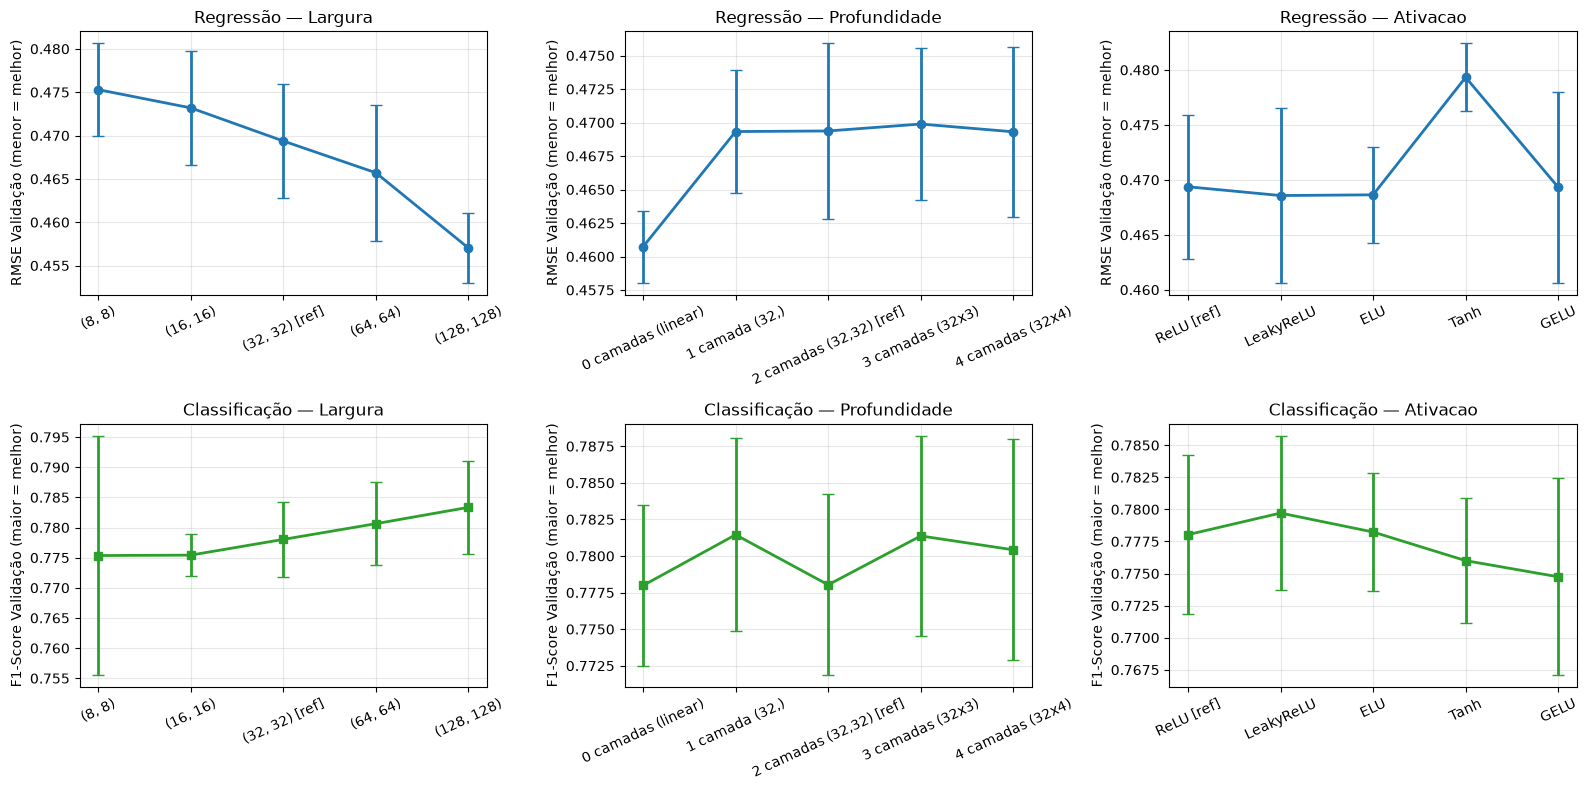

In [14]:
# Visualização comparativa (Média ± Desvio Padrão na Validação)
df_res_arq = pd.DataFrame(resumos_experimentos)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for col_idx, exp_nome in enumerate(["largura", "profundidade", "ativacao"]):
    # Linha 0: Regressão (RMSE - menor é melhor)
    sub_reg = df_res_arq[(df_res_arq["tarefa"] == "regressao") & (df_res_arq["experimento"] == exp_nome)]
    axes[0, col_idx].errorbar(
        sub_reg["valor_testado"], sub_reg["val_rmse_media"], yerr=sub_reg["val_rmse_std"],
        fmt="-o", capsize=4, color="tab:blue", linewidth=2
    )
    axes[0, col_idx].set_title(f"Regressão — {exp_nome.capitalize()}")
    axes[0, col_idx].set_ylabel("RMSE Validação (menor = melhor)")
    axes[0, col_idx].tick_params(axis="x", rotation=25)
    axes[0, col_idx].grid(True, alpha=0.3)

    # Linha 1: Classificação (F1 - maior é melhor)
    sub_cls = df_res_arq[(df_res_arq["tarefa"] == "classificacao") & (df_res_arq["experimento"] == exp_nome)]
    axes[1, col_idx].errorbar(
        sub_cls["valor_testado"], sub_cls["val_f1_media"], yerr=sub_cls["val_f1_std"],
        fmt="-s", capsize=4, color="tab:green", linewidth=2
    )
    axes[1, col_idx].set_title(f"Classificação — {exp_nome.capitalize()}")
    axes[1, col_idx].set_ylabel("F1-Score Validação (maior = melhor)")
    axes[1, col_idx].tick_params(axis="x", rotation=25)
    axes[1, col_idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/hiperparametros_arquitetura.png", dpi=150)
plt.show()

In [15]:
def avaliar_seguro(tarefa: str, exp_nome: str, rotulo: str, cfg: dict) -> dict:
    """Envolve avaliar_configuracao para tratar eventuais divergências (NaN) com lr alto."""
    try:
        return avaliar_configuracao(tarefa, exp_nome, rotulo, cfg)
    except ValueError:
        return {
            "tarefa": tarefa,
            "experimento": exp_nome,
            "valor_testado": rotulo,
            "n_params": np.nan,
            "val_loss_media": np.nan,
            "val_loss_std": np.nan,
            "val_rmse_media": np.nan,
            "val_rmse_std": np.nan,
            "val_mae_media": np.nan,
            "val_f1_media": np.nan,
            "val_f1_std": np.nan,
            "val_acc_media": np.nan,
            "val_auc_media": np.nan,
        }


grade_treino_reg = {
    "otimizador": [
        ("SGD", "SGD"),
        ("SGD+Mom", "SGD_momentum"),
        ("RMSprop", "RMSprop"),
        ("Adam [ref]", "Adam"),
        ("AdamW", "AdamW"),
    ],
    "lr": [
        ("1e-4", 1e-4),
        ("1e-3 [ref]", 1e-3),
        ("1e-2", 1e-2),
        ("1e-1", 1e-1),
        ("1.0", 1.0),
    ],
    "batch_size": [
        ("8", 8),
        ("32 [ref]", 32),
        ("128", 128),
        ("512", 512),
        ("total", "total"),
    ],
    "dropout": [
        ("0.0 [ref]", 0.0),
        ("0.1", 0.1),
        ("0.3", 0.3),
        ("0.5", 0.5),
    ],
    "weight_decay": [
        ("0 [ref]", 0.0),
        ("1e-5", 1e-5),
        ("1e-4", 1e-4),
        ("1e-3", 1e-3),
        ("1e-2", 1e-2),
    ],
}

In [16]:
resumos_etapa3 = []

for tarefa in ["regressao", "classificacao"]:
    print(f"\n{'='*65}\nTAREFA: {tarefa.upper()}\n{'='*65}")
    for exp_nome, opcoes in grade_treino_reg.items():
        print(f"\n--- Experimento: {exp_nome} ---")
        for rotulo, valor in opcoes:
            cfg = CFG_REF.copy()
            chave_cfg = "optimizer" if exp_nome == "otimizador" else exp_nome
            cfg[chave_cfg] = valor

            res = avaliar_seguro(tarefa, exp_nome, rotulo, cfg)
            resumos_experimentos.append(res)
            resumos_etapa3.append(res)

            if tarefa == "regressao":
                if np.isnan(res["val_rmse_media"]):
                    print(f"{rotulo:18s} | DIVERGIU (NaN)")
                else:
                    print(f"{rotulo:18s} | RMSE Val: {res['val_rmse_media']:.4f} ± {res['val_rmse_std']:.4f}")
            else:
                if np.isnan(res["val_f1_media"]):
                    print(f"{rotulo:18s} | DIVERGIU (NaN)")
                else:
                    print(f"{rotulo:18s} | F1 Val: {res['val_f1_media']:.4f} ± {res['val_f1_std']:.4f} | "
                          f"Acc: {res['val_acc_media']:.4f}")

df_res_e3 = pd.DataFrame(resumos_etapa3)


TAREFA: REGRESSAO

--- Experimento: otimizador ---
SGD                | RMSE Val: 0.4795 ± 0.0101
SGD+Mom            | RMSE Val: 0.4675 ± 0.0105
RMSprop            | RMSE Val: 0.4688 ± 0.0057
Adam [ref]         | RMSE Val: 0.4694 ± 0.0065
AdamW              | RMSE Val: 0.4694 ± 0.0065

--- Experimento: lr ---
1e-4               | RMSE Val: 0.4730 ± 0.0060
1e-3 [ref]         | RMSE Val: 0.4694 ± 0.0065
1e-2               | RMSE Val: 0.4632 ± 0.0105
1e-1               | RMSE Val: 0.4567 ± 0.0085
1.0                | RMSE Val: 0.5869 ± 0.0493

--- Experimento: batch_size ---
8                  | RMSE Val: 0.4684 ± 0.0075
32 [ref]           | RMSE Val: 0.4694 ± 0.0065
128                | RMSE Val: 0.4686 ± 0.0068
512                | RMSE Val: 0.4711 ± 0.0061
total              | RMSE Val: 0.4711 ± 0.0061

--- Experimento: dropout ---
0.0 [ref]          | RMSE Val: 0.4694 ± 0.0065
0.1                | RMSE Val: 0.4684 ± 0.0032
0.3                | RMSE Val: 0.4685 ± 0.0039
0.5           

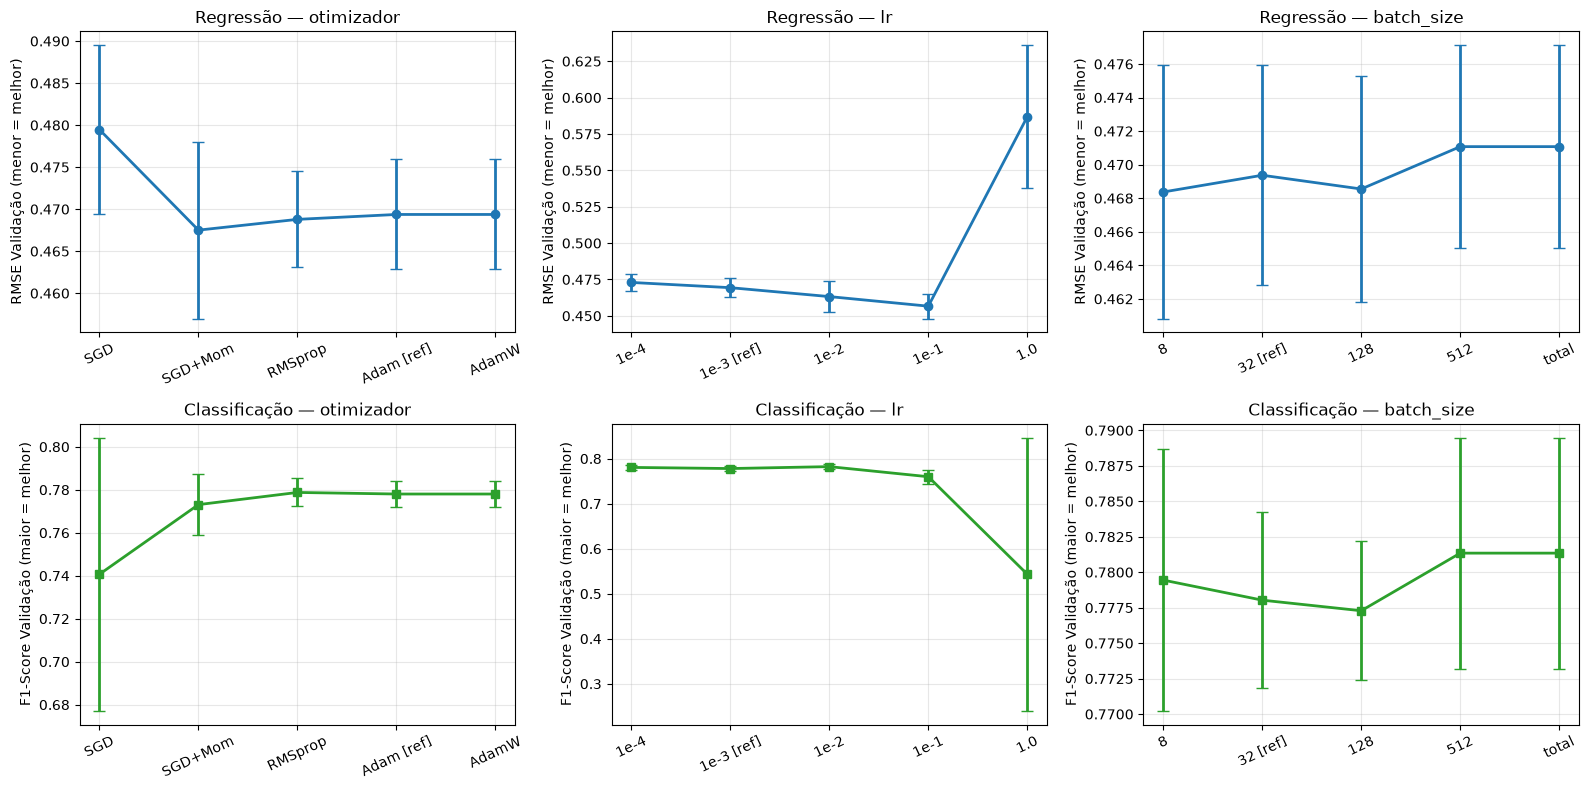

In [17]:
# Figura 1: Otimizador, Taxa de Aprendizado e Batch Size
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col_idx, exp_nome in enumerate(["otimizador", "lr", "batch_size"]):
    sub_reg = df_res_e3[(df_res_e3["tarefa"] == "regressao") & (df_res_e3["experimento"] == exp_nome)].dropna(subset=["val_rmse_media"])
    axes[0, col_idx].errorbar(
        sub_reg["valor_testado"], sub_reg["val_rmse_media"], yerr=sub_reg["val_rmse_std"],
        fmt="-o", capsize=4, color="tab:blue", linewidth=2
    )
    axes[0, col_idx].set_title(f"Regressão — {exp_nome}")
    axes[0, col_idx].set_ylabel("RMSE Validação (menor = melhor)")
    axes[0, col_idx].tick_params(axis="x", rotation=25)
    axes[0, col_idx].grid(True, alpha=0.3)

    sub_cls = df_res_e3[(df_res_e3["tarefa"] == "classificacao") & (df_res_e3["experimento"] == exp_nome)].dropna(subset=["val_f1_media"])
    axes[1, col_idx].errorbar(
        sub_cls["valor_testado"], sub_cls["val_f1_media"], yerr=sub_cls["val_f1_std"],
        fmt="-s", capsize=4, color="tab:green", linewidth=2
    )
    axes[1, col_idx].set_title(f"Classificação — {exp_nome}")
    axes[1, col_idx].set_ylabel("F1-Score Validação (maior = melhor)")
    axes[1, col_idx].tick_params(axis="x", rotation=25)
    axes[1, col_idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/hiperparametros_otimizacao.png", dpi=150)
plt.show()

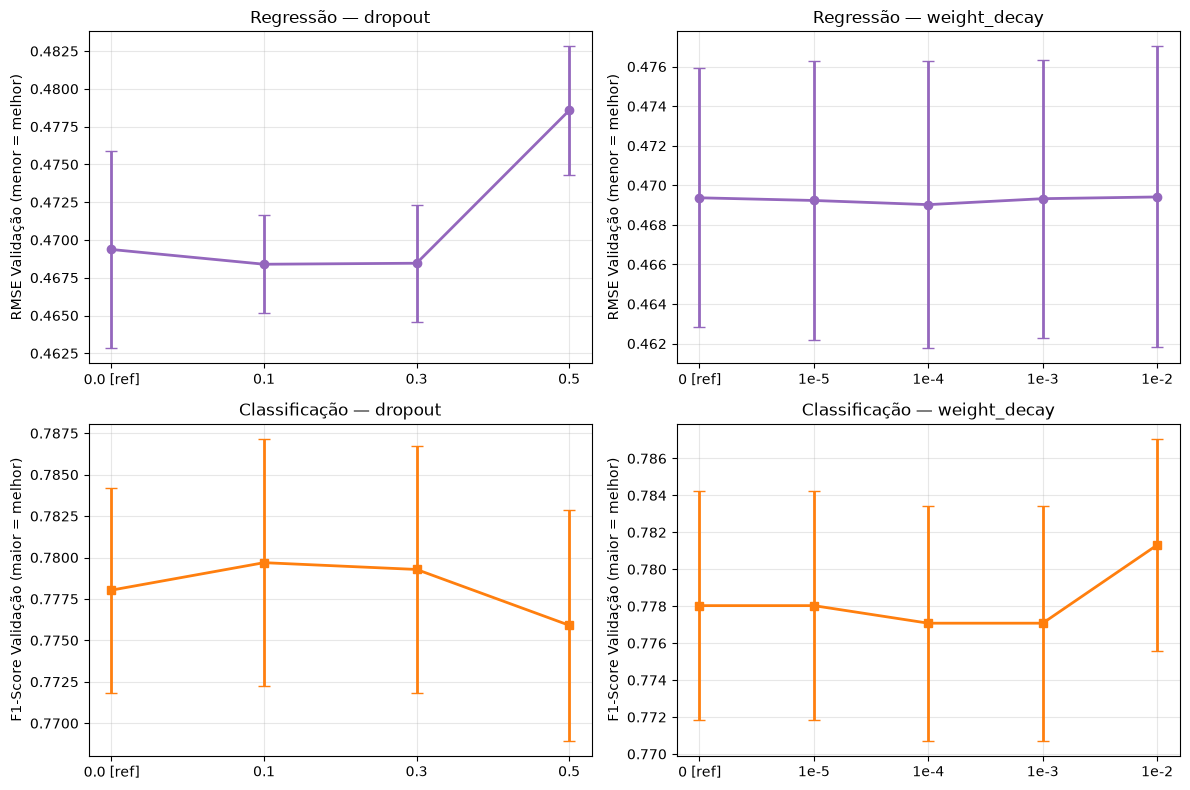

In [18]:
# Figura 2: Regularização (Dropout e Weight Decay)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col_idx, exp_nome in enumerate(["dropout", "weight_decay"]):
    sub_reg = df_res_e3[(df_res_e3["tarefa"] == "regressao") & (df_res_e3["experimento"] == exp_nome)]
    axes[0, col_idx].errorbar(
        sub_reg["valor_testado"], sub_reg["val_rmse_media"], yerr=sub_reg["val_rmse_std"],
        fmt="-o", capsize=4, color="tab:purple", linewidth=2
    )
    axes[0, col_idx].set_title(f"Regressão — {exp_nome}")
    axes[0, col_idx].set_ylabel("RMSE Validação (menor = melhor)")
    axes[0, col_idx].grid(True, alpha=0.3)

    sub_cls = df_res_e3[(df_res_e3["tarefa"] == "classificacao") & (df_res_e3["experimento"] == exp_nome)]
    axes[1, col_idx].errorbar(
        sub_cls["valor_testado"], sub_cls["val_f1_media"], yerr=sub_cls["val_f1_std"],
        fmt="-s", capsize=4, color="tab:orange", linewidth=2
    )
    axes[1, col_idx].set_title(f"Classificação — {exp_nome}")
    axes[1, col_idx].set_ylabel("F1-Score Validação (maior = melhor)")
    axes[1, col_idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../reports/figures/hiperparametros_regularizacao.png", dpi=150)
plt.show()

In [19]:
# 1. Mapa de calor de interação 2D: Largura (hidden) x Taxa de Aprendizado (lr)
larguras_grid = [
    ("(16, 16)", (16, 16)),
    ("(32, 32)", (32, 32)),
    ("(64, 64)", (64, 64)),
    ("(128, 128)", (128, 128)),
]
lrs_grid = [1e-4, 1e-3, 1e-2, 1e-1]

heatmap_reg = np.zeros((len(larguras_grid), len(lrs_grid)))
heatmap_cls = np.zeros((len(larguras_grid), len(lrs_grid)))

print("A calcular grelha de interação 2D (Largura x Taxa de Aprendizado)...")
for i, (rot_h, val_h) in enumerate(larguras_grid):
    for j, val_lr in enumerate(lrs_grid):
        cfg_2d = {**CFG_REF, "hidden": val_h, "lr": val_lr}
        rotulo_2d = f"{rot_h}_lr={val_lr}"

        r_reg = avaliar_seguro("regressao", "interacao_2d", rotulo_2d, cfg_2d)
        r_cls = avaliar_seguro("classificacao", "interacao_2d", rotulo_2d, cfg_2d)
        resumos_experimentos.extend([r_reg, r_cls])

        heatmap_reg[i, j] = r_reg["val_rmse_media"]
        heatmap_cls[i, j] = r_cls["val_f1_media"]

A calcular grelha de interação 2D (Largura x Taxa de Aprendizado)...


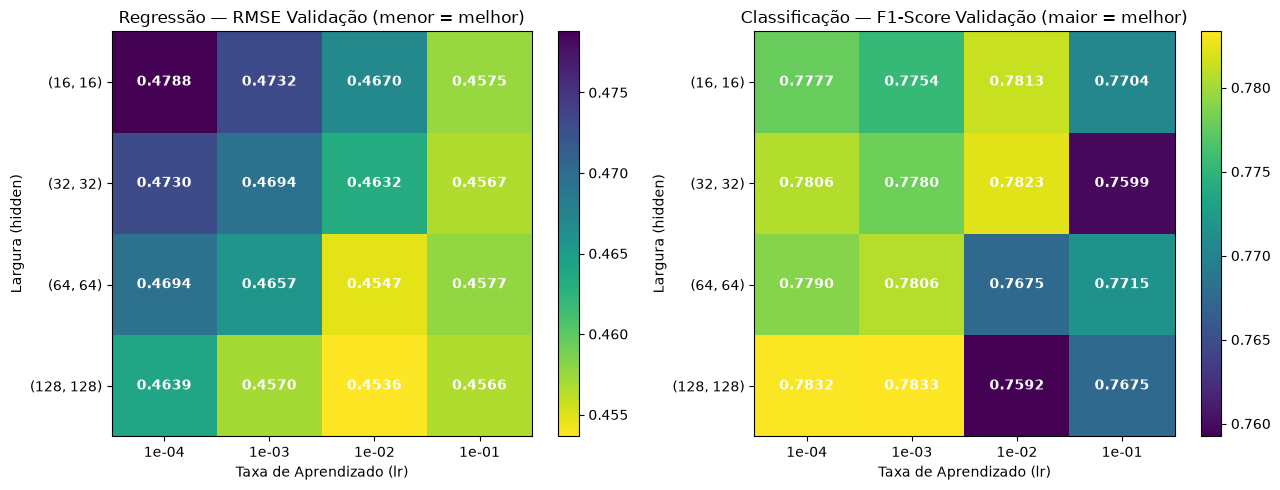

In [24]:
# Visualização dos dois mapas de calor lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im0 = axes[0].imshow(heatmap_reg, cmap="viridis_r", aspect="auto")
axes[0].set_title("Regressão — RMSE Validação (menor = melhor)")
axes[0].set_xticks(range(len(lrs_grid)))
axes[0].set_xticklabels([f"{lr:.0e}" for lr in lrs_grid])
axes[0].set_yticks(range(len(larguras_grid)))
axes[0].set_yticklabels([r[0] for r in larguras_grid])
axes[0].set_xlabel("Taxa de Aprendizado (lr)")
axes[0].set_ylabel("Largura (hidden)")
for i in range(len(larguras_grid)):
    for j in range(len(lrs_grid)):
        axes[0].text(j, i, f"{heatmap_reg[i, j]:.4f}", ha="center", va="center", color="white", fontweight="bold")
plt.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(heatmap_cls, cmap="viridis", aspect="auto")
axes[1].set_title("Classificação — F1-Score Validação (maior = melhor)")
axes[1].set_xticks(range(len(lrs_grid)))
axes[1].set_xticklabels([f"{lr:.0e}" for lr in lrs_grid])
axes[1].set_yticks(range(len(larguras_grid)))
axes[1].set_yticklabels([r[0] for r in larguras_grid])
axes[1].set_xlabel("Taxa de Aprendizado (lr)")
axes[1].set_ylabel("Largura (hidden)")
for i in range(len(larguras_grid)):
    for j in range(len(lrs_grid)):
        axes[1].text(j, i, f"{heatmap_cls[i, j]:.4f}", ha="center", va="center", color="white", fontweight="bold")
plt.colorbar(im1, ax=axes[1])

plt.tight_layout()
plt.savefig("../reports/figures/heatmap_interacao_hp.png", dpi=150)
plt.show()

In [26]:
# 2. Candidatos combinados finais (ajustados apenas pela validação)
candidatos_reg = {
    "cand1_128x128_lr1e-2_elu": {**CFG_REF, "hidden": (128, 128), "lr": 1e-2, "activation": "ELU"},
    "cand2_128x128_lr1e-1_relu": {**CFG_REF, "hidden": (128, 128), "lr": 1e-1, "activation": "ReLU"},
    "cand3_64x64_lr1e-2_elu_do01": {**CFG_REF, "hidden": (64, 64), "lr": 1e-2, "activation": "ELU", "dropout": 0.1},
    "cand4_linear_lr1e-2": {**CFG_REF, "hidden": (), "lr": 1e-2},
}

candidatos_cls = {
    "cand1_128x128_lr1e-2_leaky": {**CFG_REF, "hidden": (128, 128), "lr": 1e-2, "activation": "LeakyReLU"},
    "cand2_128x128_lr1e-3_wd1e-2": {**CFG_REF, "hidden": (128, 128), "lr": 1e-3, "weight_decay": 1e-2},
    "cand3_64x64_lr1e-2_leaky_do01": {**CFG_REF, "hidden": (64, 64), "lr": 1e-2, "activation": "LeakyReLU", "dropout": 0.1},
    "cand4_128x128_lr1e-2_wd1e-2": {**CFG_REF, "hidden": (128, 128), "lr": 1e-2, "activation": "LeakyReLU", "weight_decay": 1e-2},
}

In [27]:
# 3. Exportação obrigatória dos logs e tabela-resumo
df_logs_completo = pd.DataFrame(historico_logs)
df_logs_completo.to_csv("../logs/hiperparametros.csv", index=False)

df_resumo_completo = pd.DataFrame(resumos_experimentos)
df_resumo_completo.to_csv("../reports/tables/resumo_hiperparametros.csv", index=False)

# Identificação automática das melhores configurações (entre todas as testadas na validação)
melhor_reg = df_resumo_completo[df_resumo_completo["tarefa"] == "regressao"].sort_values("val_rmse_media").iloc[0]
melhor_cls = df_resumo_completo[df_resumo_completo["tarefa"] == "classificacao"].sort_values("val_f1_media", ascending=False).iloc[0]

print(f"\nGuardadas {len(df_logs_completo)} execuções individuais em ../logs/hiperparametros.csv")
print(f"Vencedor Regressão (Validação): {melhor_reg['experimento']} -> {melhor_reg['valor_testado']} "
      f"(RMSE = {melhor_reg['val_rmse_media']:.4f} ± {melhor_reg['val_rmse_std']:.4f})")
print(f"Vencedor Classificação (Validação): {melhor_cls['experimento']} -> {melhor_cls['valor_testado']} "
      f"(F1 = {melhor_cls['val_f1_media']:.4f} ± {melhor_cls['val_f1_std']:.4f})")


Guardadas 560 execuções individuais em ../logs/hiperparametros.csv
Vencedor Regressão (Validação): interacao_2d -> (128, 128)_lr=0.01 (RMSE = 0.4536 ± 0.0100)
Vencedor Classificação (Validação): largura -> (128, 128) (F1 = 0.7833 ± 0.0078)
